# EN3150 Assignment 03: Model B (Depthwise-Separable CNN), shared pipeline

This notebook retrains **Model B** with exactly the same pipeline as `Model_A/src/ModelA.ipynb`, on the same
machine, so the Model A vs Model B comparison (including training time per epoch) only differs in the
convolution type.

| Held identical to Model A | Value |
|---|---|
| Data | `splits/*.csv` (70/15/15, 18,648 / 3,996 / 3,996), 64x64 input |
| Preprocessing and augmentation | `Common/dataset.py` (colour jitter, rotation, small affine, normalise to [-1, 1]) |
| Training loop | `Common/training.py` `train_model` (best-validation-loss weights restored) |
| Optimizer | Read from `results/Optimizer/selected_optimizer.txt` (Adam, lr = 1e-3) |
| Epochs / batch size / loss | 30 / 32 / cross-entropy |
| Evaluation | `Common/evaluation.py` (same metrics, plots, size and timing functions) |

It replaces the group's earlier Model B notebook, which remains available in the git history. Running this
notebook overwrites the `model_b_*` files in `results/`.

In [1]:
import json
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce GTX 1660 Ti


In [4]:
def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

DATA_ROOT = PROJECT_ROOT / "data" / "gtsrb"
SPLIT_DIR = PROJECT_ROOT / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "Model_B"
METRICS_DIR = RESULTS_DIR / "Model_B"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: E:\UOM resourses\Sem 5\Pattern Recognition\Assignment 3


In [5]:
from Common.dataset import create_dataloaders
from Common.models import ModelB, count_parameters
from Common.training import train_model, create_optimizer
from Common.evaluation import (
    get_predictions,
    calculate_metrics,
    plot_training_curves,
    plot_confusion_matrix,
    print_classification_report,
    total_parameters,
    estimated_fp32_size_kb,
    save_model_and_get_size,
    measure_inference_time
)

## 1. Data preparation

The shared split files are loaded and wrapped in data loaders by `Common/dataset.py`. Images are resized to
$64 \times 64$; only the training set is augmented.

In [6]:
train_df = pd.read_csv(SPLIT_DIR / "train_split.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_split.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_split.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 18648
Validation: 3996
Test: 3996


In [7]:
train_loader, val_loader, test_loader = create_dataloaders(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    data_root=DATA_ROOT,
    batch_size=32,
    num_workers=0
)

### 1.1 Split checks

Confirm the 70/15/15 proportions, that no image appears in more than one split, and that all 43 classes are
present in every split.

In [8]:
total = len(train_df) + len(val_df) + len(test_df)
print(
    f"Split proportions: train={len(train_df) / total:.1%}, "
    f"validation={len(val_df) / total:.1%}, test={len(test_df) / total:.1%}"
)

train_paths, val_paths, test_paths = set(train_df.Path), set(val_df.Path), set(test_df.Path)
assert not train_paths & val_paths
assert not train_paths & test_paths
assert not val_paths & test_paths
print("Splits are disjoint.")

class_table = pd.DataFrame({
    "Train": train_df.ClassId.value_counts(),
    "Validation": val_df.ClassId.value_counts(),
    "Test": test_df.ClassId.value_counts()
}).sort_index()
print("Classes represented (train/validation/test):", *class_table.notna().sum().tolist())
class_table

Split proportions: train=70.0%, validation=15.0%, test=15.0%
Splits are disjoint.
Classes represented (train/validation/test): 43 43 43


,Train,Validation,Test
ClassId,,,
0,117,14,19
1,1051,226,223
2,1029,238,233
3,674,138,148
4,910,189,221
5,866,185,209
6,221,32,47
7,669,136,155
8,678,138,144


### 1.2 Batch checks and sample images

Image batch shape: (32, 3, 64, 64)
Image values: min=-1.000, max=1.000
Batch checks passed.


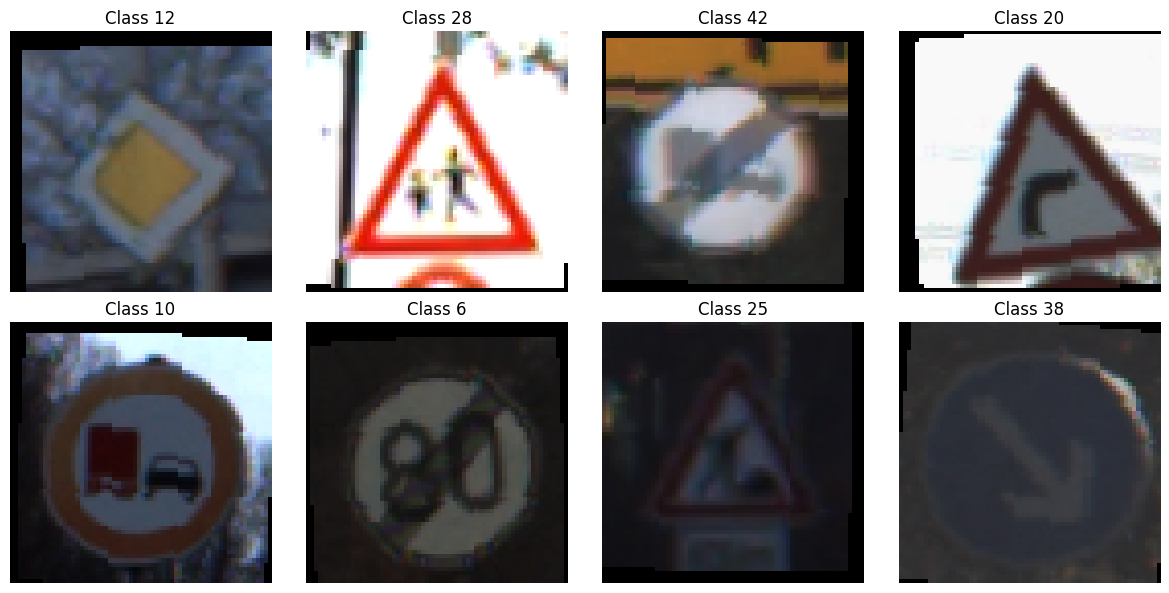

In [9]:
images, labels = next(iter(train_loader))

print(f"Image batch shape: {tuple(images.shape)}")
print(f"Image values: min={images.min().item():.3f}, max={images.max().item():.3f}")
assert images.shape[1:] == (3, 64, 64)
assert torch.isfinite(images).all()
assert labels.min() >= 0 and labels.max() < 43
print("Batch checks passed.")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow((image.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
    ax.set_title(f"Class {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Model B architecture

Same four-block layout and `3 -> 16 -> 32 -> 32 -> 32` channels as Model A, but each standard $3 \times 3$
convolution is replaced by a **depthwise separable convolution**: a depthwise $3 \times 3$ convolution (one filter
per input channel, `groups=in_channels`, no bias) followed by a pointwise $1 \times 1$ convolution that mixes the
channels, then ReLU and `MaxPool2d(2x2)`. The classifier is the same `Flatten -> Linear(512, 43)`.

| Block | Depthwise 3x3 | Pointwise 1x1 | Parameters | Model A equivalent |
|---|---|---|---|---|
| 3 -> 16 | 3·9 = 27 | 3·16 + 16 = 64 | 91 | 448 |
| 16 -> 32 | 16·9 = 144 | 16·32 + 32 = 544 | 688 | 4,640 |
| 32 -> 32 | 32·9 = 288 | 32·32 + 32 = 1,056 | 1,344 | 9,248 |
| 32 -> 32 | 288 | 1,056 | 1,344 | 9,248 |
| Linear 512 -> 43 | | | 22,059 | 22,059 |
| **Total** | | | **25,526** | **45,643** |

Multiply-accumulate operations per $64 \times 64$ image: Model A ≈ **9,459,200 MACs**, Model B ≈ **1,420,800 MACs**
(about **85% fewer**). The convolution layers shrink from 23,584 to 3,467 parameters, so the linear classifier now
holds about 86% of Model B's parameters. Model B is well under the 100,000-parameter limit.

ReLU is used throughout: it is a single comparison per value (`max(0, x)`), avoiding the exponentials needed
by sigmoid or tanh, which is cheaper on microcontrollers and suits integer quantisation.

In [10]:
model_b = ModelB().to(device)
print(model_b)

parameters_b = count_parameters(model_b)
print("Model B trainable parameters:", parameters_b)
assert parameters_b == 25526

for name, parameter in model_b.named_parameters():
    print(f"{name:22s} {str(tuple(parameter.shape)):18s} {parameter.numel():>7,}")

ModelB(
  (features): Sequential(
    (0): DepthwiseSeparableConv(
      (depthwise): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=3, bias=False)
      (pointwise): Conv2d(3, 16, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): DepthwiseSeparableConv(
      (depthwise): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
      (pointwise): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): DepthwiseSeparableConv(
      (depthwise): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
      (pointwise): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6)

### 2.1 Forward-pass smoke check

In [11]:
model_b.eval()
with torch.inference_mode():
    logits = model_b(images.to(device))
assert logits.shape == (images.shape[0], 43)
assert torch.isfinite(logits).all()
print(f"Smoke check passed: {tuple(images.shape)} -> {tuple(logits.shape)}")

Smoke check passed: (32, 3, 64, 64) -> (32, 43)


## 3. Training

Same optimizer, epochs and seed as Model A. The model and optimizer are recreated after re-seeding so the
run is reproducible.

In [12]:
selected_optimizer = (RESULTS_DIR / "Optimizer" / "selected_optimizer.txt").read_text().strip()
print("Final optimizer:", selected_optimizer)

Final optimizer: Adam


In [13]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


model_b = ModelB().to(device)

criterion = nn.CrossEntropyLoss()

optimizer_b = create_optimizer(selected_optimizer, model_b.parameters())

In [14]:
model_b, history_b = train_model(
    model=model_b,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b,
    criterion=criterion,
    epochs=30,
    device=device
)

METRICS_DIR.mkdir(parents=True, exist_ok=True)
with (METRICS_DIR / "model_b_history.json").open("w", encoding="utf-8") as history_file:
    json.dump(history_b, history_file, indent=2)

Epoch 01/30 | Train Loss: 2.8361 | Train Acc: 0.2060 | Val Loss: 1.7702 | Val Acc: 0.4452 | Time: 46.34s
Epoch 02/30 | Train Loss: 1.6160 | Train Acc: 0.4867 | Val Loss: 1.2085 | Val Acc: 0.6021 | Time: 47.28s
Epoch 03/30 | Train Loss: 1.2020 | Train Acc: 0.6094 | Val Loss: 0.9199 | Val Acc: 0.6824 | Time: 47.00s
Epoch 04/30 | Train Loss: 0.9174 | Train Acc: 0.7003 | Val Loss: 0.6366 | Val Acc: 0.7768 | Time: 47.23s
Epoch 05/30 | Train Loss: 0.7182 | Train Acc: 0.7638 | Val Loss: 0.4849 | Val Acc: 0.8408 | Time: 54.06s
Epoch 06/30 | Train Loss: 0.5731 | Train Acc: 0.8116 | Val Loss: 0.4104 | Val Acc: 0.8559 | Time: 50.02s
Epoch 07/30 | Train Loss: 0.4926 | Train Acc: 0.8345 | Val Loss: 0.3495 | Val Acc: 0.8871 | Time: 51.83s
Epoch 08/30 | Train Loss: 0.4305 | Train Acc: 0.8591 | Val Loss: 0.2946 | Val Acc: 0.9059 | Time: 46.75s
Epoch 09/30 | Train Loss: 0.3830 | Train Acc: 0.8730 | Val Loss: 0.2522 | Val Acc: 0.9162 | Time: 49.34s
Epoch 10/30 | Train Loss: 0.3584 | Train Acc: 0.8800 | 

## 4. Evaluation

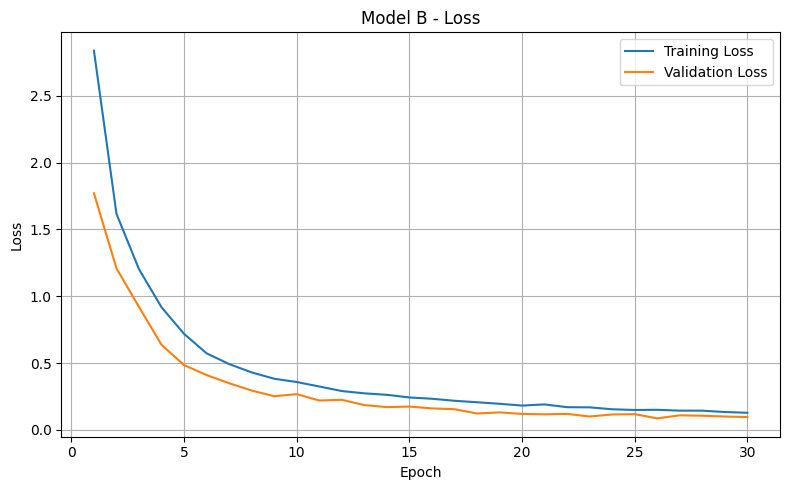

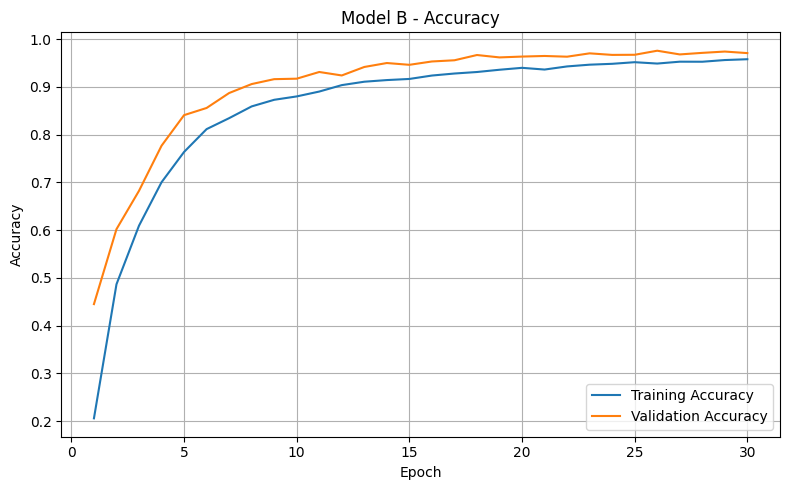

In [15]:
plot_training_curves(
    history=history_b,
    model_name="Model B",
    save_dir=FIGURES_DIR
)

In [16]:
y_true_b, y_pred_b = get_predictions(model_b, test_loader, device)

metrics_b = calculate_metrics(y_true_b, y_pred_b)

print(metrics_b)

{'Test Accuracy': 0.9772272272272272, 'Macro Precision': 0.980785397092863, 'Macro Recall': 0.9820656361357541}


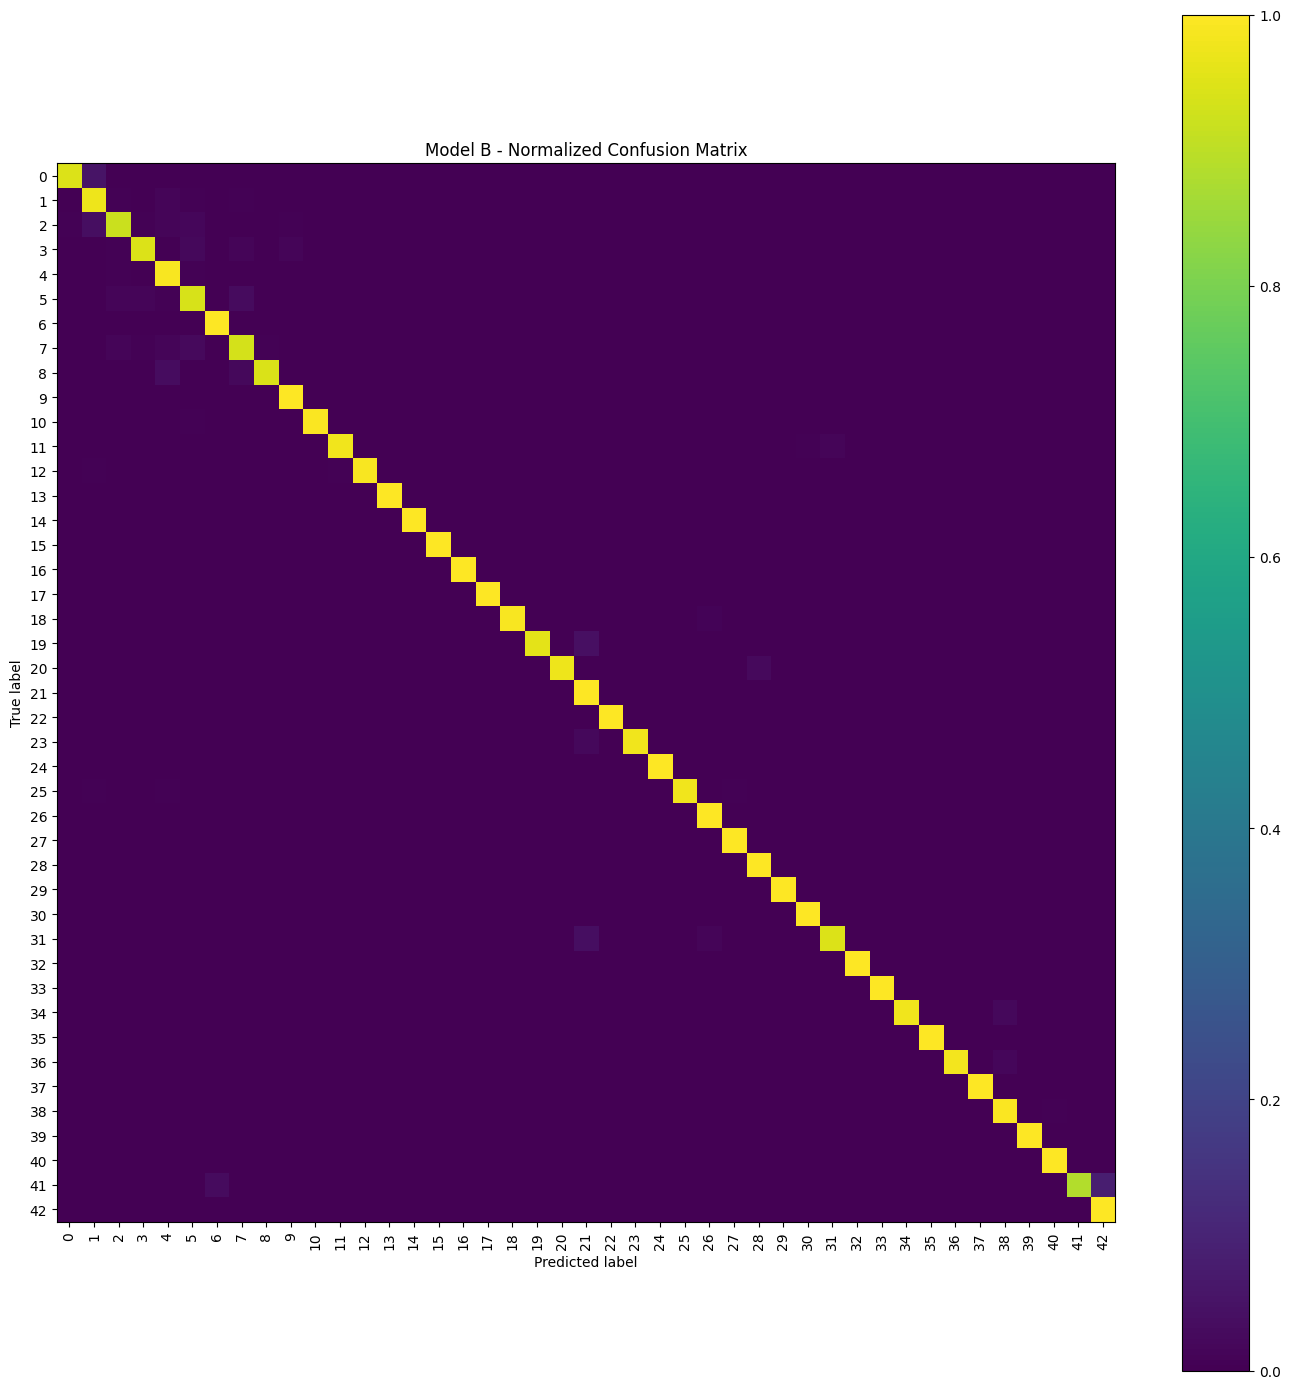

In [17]:
plot_confusion_matrix(
    y_true_b,
    y_pred_b,
    model_name="Model B",
    save_dir=FIGURES_DIR
)

In [18]:
report_b = classification_report(y_true_b, y_pred_b, output_dict=True, zero_division=0)
print_classification_report(y_true_b, y_pred_b)

with (METRICS_DIR / "model_b_classification_report.json").open("w", encoding="utf-8") as report_file:
    json.dump(report_b, report_file, indent=2)
np.savetxt(
    METRICS_DIR / "model_b_confusion_matrix.csv",
    confusion_matrix(y_true_b, y_pred_b, labels=list(range(43))),
    fmt="%d",
    delimiter=","
)

              precision    recall  f1-score   support

           0     0.9474    0.9474    0.9474        19
           1     0.9476    0.9731    0.9602       223
           2     0.9640    0.9185    0.9407       233
           3     0.9655    0.9459    0.9556       148
           4     0.9359    0.9910    0.9626       221
           5     0.9333    0.9378    0.9356       209
           6     0.9792    1.0000    0.9895        47
           7     0.9236    0.9355    0.9295       155
           8     0.9927    0.9444    0.9680       144
           9     0.9810    1.0000    0.9904       155
          10     1.0000    0.9949    0.9975       197
          11     0.9927    0.9784    0.9855       139
          12     1.0000    0.9906    0.9953       213
          13     1.0000    1.0000    1.0000       213
          14     1.0000    1.0000    1.0000        78
          15     1.0000    1.0000    1.0000        82
          16     1.0000    1.0000    1.0000        34
          17     1.0000    

## 5. Edge-deployment measurements

In [19]:
average_epoch_time_b = np.mean(history_b["epoch_time"])

print("Average epoch time:", average_epoch_time_b)

Average epoch time: 47.84791759333384


In [20]:
parameters_b = total_parameters(model_b)

estimated_size_b = estimated_fp32_size_kb(model_b)

model_b_path = PROJECT_ROOT / "checkpoints" / "model_b_final.pth"

actual_size_b = save_model_and_get_size(model_b, model_b_path)

print("Parameters:", parameters_b)
print("Estimated size:", estimated_size_b, "KB")
print("Actual size:", actual_size_b, "KB")

Parameters: 25526
Estimated size: 99.7109375 KB
Actual size: 105.7353515625 KB


In [21]:
inference_time_b = measure_inference_time(model_b, test_loader, device)

print("Inference time:", inference_time_b, "ms/image")

Inference time: 0.3418770625239631 ms/image


In [22]:
model_b_results = {
    "Model": "Model B",
    "Parameters": parameters_b,
    "Estimated FP32 Size (KB)": estimated_size_b,
    "Actual Model Size (KB)": actual_size_b,
    "Average Epoch Time (s)": average_epoch_time_b,
    "Inference Time (ms/image)": inference_time_b,
    "Test Accuracy": metrics_b["Test Accuracy"],
    "Macro Precision": metrics_b["Macro Precision"],
    "Macro Recall": metrics_b["Macro Recall"]
}

model_b_df = pd.DataFrame([model_b_results])

model_b_df.to_csv(METRICS_DIR / "model_b_metrics.csv", index=False)

model_b_df

,Model,Parameters,Estimated FP32 Size (KB),Actual Model Size (KB),Average Epoch Time (s),Inference Time (ms/image),Test Accuracy,Macro Precision,Macro Recall
0,Model B,25526,99.710938,105.735352,47.847918,0.341877,0.977227,0.980785,0.982066
